# Titanic – Exploratory Data Analysis (EDA)
**Module:** IB2AD0 Data Science & Generative AI – Session 2 seminar practice

**Goal:** look at the Titanic passenger data *before* any modelling. We check:
1. **Structure** – what is in the data?
2. **Issues** – what is missing, odd or messy?
3. **Patterns** – which groups survived more?

**Business link:** any business dataset (customers, orders) needs the same checks. Before we trust a result, we must know what is missing, why, and whether the gaps are random.

*AI use: I used Claude (GenAI) to help write and explain this code, as the module allows.*

## 0. Setup – load libraries and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)

**Getting the data.** In Colab, the file must be uploaded into the session first.
This cell looks for `titanic.csv`. If it is not there, it opens an upload box (Colab only).

In [2]:
import os

if not os.path.exists('titanic.csv'):
    try:
        from google.colab import files   # only works in Google Colab
        files.upload()                   # choose titanic.csv from your computer
    except ImportError:
        print('Not in Colab: put titanic.csv in the same folder as this notebook.')

df = pd.read_csv('titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Structure – what is in the data?

In [3]:
# Rows = passengers, columns = information about each passenger
print('Rows, columns:', df.shape)
df.dtypes

Rows, columns: (891, 12)


PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [4]:
# Basic statistics for the number columns (count, mean, min, max...)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


**Note:** `Survived`, `Pclass` and `Embarked` are **codes for categories**, not real amounts.
An average class of 2.3 means nothing, so we treat them as labels.

In [5]:
for col in ['Survived', 'Pclass', 'Sex', 'Embarked']:
    print(df[col].value_counts(dropna=False).sort_index(), '\n')

Survived
0    549
1    342
Name: count, dtype: int64 

Pclass
1    216
2    184
3    491
Name: count, dtype: int64 

Sex
female    314
male      577
Name: count, dtype: int64 

Embarked
C      168
Q       77
S      644
NaN      2
Name: count, dtype: int64 



## 2. Issues – missing, odd and messy data

### 2.1 Missing values

In [6]:
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(1)
})
missing[missing['missing'] > 0]

,missing,missing_%
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


**Is the missing data random?** Check missing Age and Cabin by class.

In [7]:
(df.groupby('Pclass')[['Age', 'Cabin']]
   .apply(lambda g: (g.isna().mean() * 100).round(1)))

,Age,Cabin
Pclass,,
1,13.9,18.5
2,6.0,91.3
3,27.7,97.6


In [8]:
# Missing Age by survival
(df.groupby('Survived')['Age'].apply(lambda s: s.isna().mean() * 100)).round(1)

Survived
0    22.8
1    15.2
Name: Age, dtype: float64

**What I see:** Cabin is missing far more in class 2 and 3. Age is missing more in class 3 and among non-survivors.
So the gaps are **not random** – filling them with one simple number could bias results.

In [9]:
# The 2 passengers with no port (Embarked)
df[df['Embarked'].isna()][['Name', 'Pclass', 'Fare', 'Cabin', 'Ticket']]

,Name,Pclass,Fare,Cabin,Ticket
61,"Icard, Miss. Amelie",1,80.0,B28,113572
829,"Stone, Mrs. George Nelson (Martha Evelyn)",1,80.0,B28,113572


### 2.2 Duplicates

In [10]:
print('Duplicate rows:          ', df.duplicated().sum())
print('Duplicate PassengerId:   ', df['PassengerId'].duplicated().sum())
print('Passengers sharing a ticket:', (df.groupby('Ticket')['Ticket'].transform('count') > 1).sum())

Duplicate rows:           0
Duplicate PassengerId:    0


Passengers sharing a ticket: 344


### 2.3 Odd values and outliers in Fare

In [11]:
# Fare = 0 is not a real ticket price
print('Passengers with Fare = 0:', (df['Fare'] == 0).sum())
df[df['Fare'] == 0][['Name', 'Pclass', 'Age']]

Passengers with Fare = 0: 15


,Name,Pclass,Age
179,"Leonard, Mr. Lionel",3,36.0
263,"Harrison, Mr. William",1,40.0
271,"Tornquist, Mr. William Henry",3,25.0
277,"Parkes, Mr. Francis ""Frank""",2,NaN
302,"Johnson, Mr. William Cahoone Jr",3,19.0
413,"Cunningham, Mr. Alfred Fleming",2,NaN
466,"Campbell, Mr. William",2,NaN
481,"Frost, Mr. Anthony Wood ""Archie""",2,NaN
597,"Johnson, Mr. Alfred",3,49.0
633,"Parr, Mr. William Henry Marsh",1,NaN


In [12]:
# Outliers with the IQR rule: above Q3 + 1.5 * IQR
q1, q3 = df['Fare'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print('Upper fence:', round(upper, 2))
print('Fares above it:', (df['Fare'] > upper).sum())
print('Mean fare:', round(df['Fare'].mean(), 2), '| Median fare:', round(df['Fare'].median(), 2))
print('Skew (lean to one side):', round(df['Fare'].skew(), 2))

Upper fence: 65.63
Fares above it: 116
Mean fare: 32.2 | Median fare: 14.45
Skew (lean to one side): 4.79


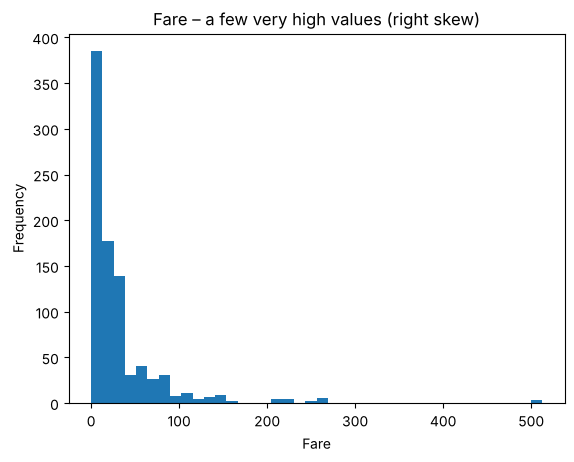

In [13]:
df['Fare'].plot(kind='hist', bins=40, title='Fare – a few very high values (right skew)')
plt.xlabel('Fare'); plt.show()

In [14]:
# Highest fares: groups on one ticket show the same fare number
df.nlargest(6, 'Fare')[['Name', 'Pclass', 'Fare', 'Ticket']]

,Name,Pclass,Fare,Ticket
258,"Ward, Miss. Anna",1,512.3292,PC 17755
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,PC 17755
737,"Lesurer, Mr. Gustave J",1,512.3292,PC 17755
27,"Fortune, Mr. Charles Alexander",1,263.0000,19950
88,"Fortune, Miss. Mabel Helen",1,263.0000,19950
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,19950


### 2.4 Odd values in Age

In [15]:
age = df['Age'].dropna()
print('Min age:', age.min(), '| Max age:', age.max())
print('Babies under 1 year:', (age < 1).sum())
print('Non-whole ages (babies + ages like 34.5):', (age % 1 != 0).sum())

Min age: 0.42 | Max age: 80.0
Babies under 1 year: 7
Non-whole ages (babies + ages like 34.5): 25


### 2.5 Messy text columns

In [16]:
# Several cabins in one cell, e.g. 'C23 C25 C27'
print('Cabin cells with several cabins:', df['Cabin'].dropna().str.contains(' ').sum())

# Titles are hidden inside the Name text
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.')
df['Title'].value_counts()

Cabin cells with several cabins: 24


Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

### 2.6 Summary of issues and cleaning ideas
| Issue | Cleaning idea (to discuss) |
|---|---|
| Cabin mostly missing | Drop it, or make a `HasCabin` yes/no feature |
| Age missing (~20%) | Fill with median **per class or title**, not one number |
| Embarked missing (2) | Fill using the same ticket / most common port |
| Fare = 0 | Treat as missing or flag it |
| Fare outliers / skew | Cap values or use a log scale |
| Fare is per ticket | Divide by number of people on the ticket |
| Titles inside Name | Extract `Title` as a new feature |

## 3. Patterns – who survived?

In [17]:
print('Overall survival %:', round(df['Survived'].mean() * 100, 1))

def survival(col):
    # survival % and number of passengers per group
    return (df.groupby(col, observed=True)['Survived']
              .agg(survival_pct='mean', passengers='count')
              .assign(survival_pct=lambda t: (t['survival_pct'] * 100).round(1)))

Overall survival %: 38.4


In [18]:
survival('Sex')

,survival_pct,passengers
Sex,,
female,74.2,314
male,18.9,577


In [19]:
survival('Pclass')

,survival_pct,passengers
Pclass,,
1,63.0,216
2,47.3,184
3,24.2,491


In [20]:
# Sex and class together (% survived)
(df.pivot_table(index='Sex', columns='Pclass', values='Survived', aggfunc='mean') * 100).round(1)

Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


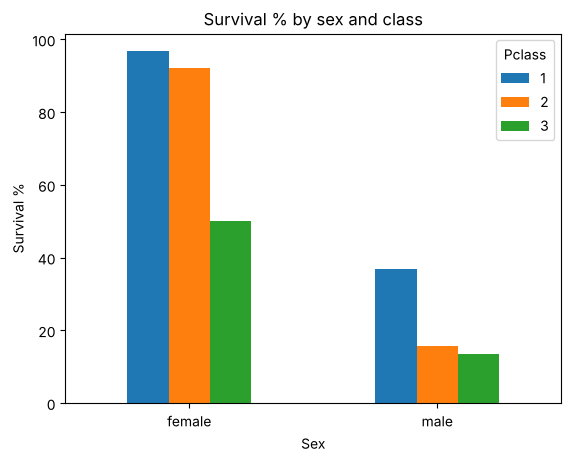

In [21]:
survival(['Sex', 'Pclass'])['survival_pct'].unstack().plot(kind='bar', title='Survival % by sex and class')
plt.ylabel('Survival %'); plt.xticks(rotation=0); plt.show()

### New features (feature engineering)

In [22]:
# Feature engineering = making new, useful columns from raw data
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['FamilyGroup'] = pd.cut(df['FamilySize'], [0, 1, 4, 20], labels=['alone (1)', 'small (2-4)', 'large (5+)'])
df['AgeBand'] = pd.cut(df['Age'], [0, 12, 18, 30, 50, 80])
df['HasCabin'] = df['Cabin'].notna()
df['FareBand'] = pd.qcut(df['Fare'], 4)

In [23]:
survival('AgeBand')

,survival_pct,passengers
AgeBand,,
"(0, 12]",58.0,69
"(12, 18]",42.9,70
"(18, 30]",35.6,270
"(30, 50]",42.3,241
"(50, 80]",34.4,64


In [24]:
survival('FamilyGroup')

,survival_pct,passengers
FamilyGroup,,
alone (1),30.4,537
small (2-4),57.9,292
large (5+),16.1,62


In [25]:
# Small groups give shaky numbers – look at the counts
survival('FamilySize')

,survival_pct,passengers
FamilySize,,
1,30.4,537
2,55.3,161
3,57.8,102
4,72.4,29
5,20.0,15
6,13.6,22
7,33.3,12
8,0.0,6
11,0.0,7


In [26]:
survival('Embarked')

,survival_pct,passengers
Embarked,,
C,55.4,168
Q,39.0,77
S,33.7,644


In [27]:
# Is port really class in disguise? Passengers by port and class
pd.crosstab(df['Embarked'], df['Pclass'])

Pclass,1,2,3
Embarked,,,
C,85,17,66
Q,2,3,72
S,127,164,353


In [28]:
survival('HasCabin')

,survival_pct,passengers
HasCabin,,
False,30.0,687
True,66.7,204


In [29]:
survival('FareBand')

,survival_pct,passengers
FareBand,,
"(-0.001, 7.91]",19.7,223
"(7.91, 14.454]",30.4,224
"(14.454, 31.0]",45.5,222
"(31.0, 512.329]",58.1,222


In [30]:
# Correlation with survival (number columns only). Range -1 to +1, near 0 = weak
df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']].corr()['Survived'].round(2)

Survived      1.00
Pclass       -0.34
Age          -0.08
SibSp        -0.04
Parch         0.08
Fare          0.26
FamilySize    0.02
Name: Survived, dtype: float64

In [31]:
survival('Title').sort_values('passengers', ascending=False).head(6)

,survival_pct,passengers
Title,,
Mr,15.7,517
Miss,69.8,182
Mrs,79.2,125
Master,57.5,40
Dr,42.9,7
Rev,0.0,6


## 4. Conclusions
- **Sex is the strongest pattern:** women ~74% survived, men ~19%.
- **Class is second:** class 1 ~63%, class 3 ~24%. Women in class 1 and 2 survived ~9 in 10.
- **Port looks important but may be class in disguise:** port C has many class 1 passengers.
- **HasCabin and Fare** mostly repeat the class signal.
- **Age alone is weak** (correlation about -0.08), but young children did better.
- **Small groups are shaky:** e.g. family size 8 has only 6 people.
- **Missing data is not random**, so it can itself be a clue (missing cabin ≈ lower class).

**Business takeaway:** check who is missing and why before trusting any result, and watch for hidden links (like port → class) before claiming a cause.